<a href="https://colab.research.google.com/github/govardhansnair/Black-Scholes_Options_Pricing_Model/blob/main/03_Live_Black_Scholes_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter stock ticker (Example: AAPL): aapl
Enter risk-free rate in % (Example: 4.5): 5

Current available stock price: 353.56

Current available stock price: 353.56
Annualised volatility: 24.94 %

Available expiry dates:
0 : 2026-11-18
1 : 2026-11-20
2 : 2026-11-23
3 : 2026-11-25
4 : 2026-11-27
5 : 2026-12-04
6 : 2026-12-11
7 : 2026-12-18
8 : 2026-12-24
9 : 2026-12-31
10 : 2027-01-15
11 : 2027-02-19
12 : 2027-03-19
13 : 2027-04-16
14 : 2027-06-17
15 : 2027-09-17
16 : 2027-12-17
17 : 2028-01-21
18 : 2028-03-17
19 : 2028-06-16
20 : 2028-12-15
21 : 2029-01-19

Select expiry number: 20

Available strike prices:
[5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0, 120.0, 125.0, 130.0, 135.0, 140.0, 145.0, 150.0, 155.0, 160.0, 165.0, 170.0, 175.0, 180.0, 185.0, 190.0, 195.0, 200.0, 210.0, 220.0, 230.0, 240.0, 250.0, 260.0, 270.0, 280.0, 290.0, 300.0, 310.0, 320.0, 330.0, 340.0, 350.0, 360.0, 370.0, 380.0, 390.0, 400.0, 410.0, 420.0, 430.0, 440.0, 45

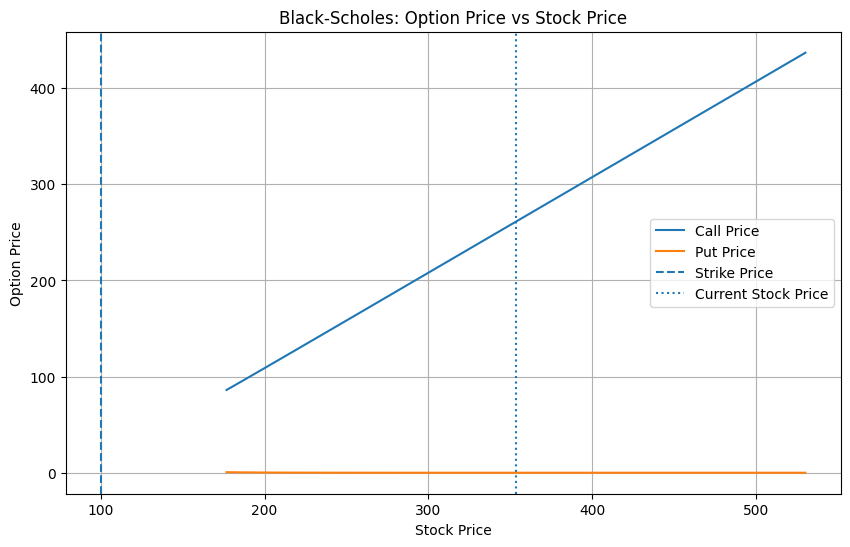

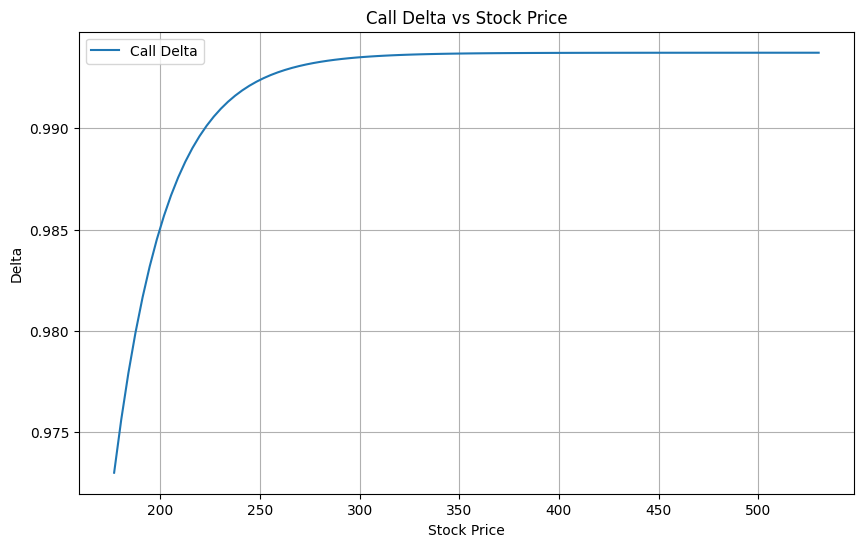

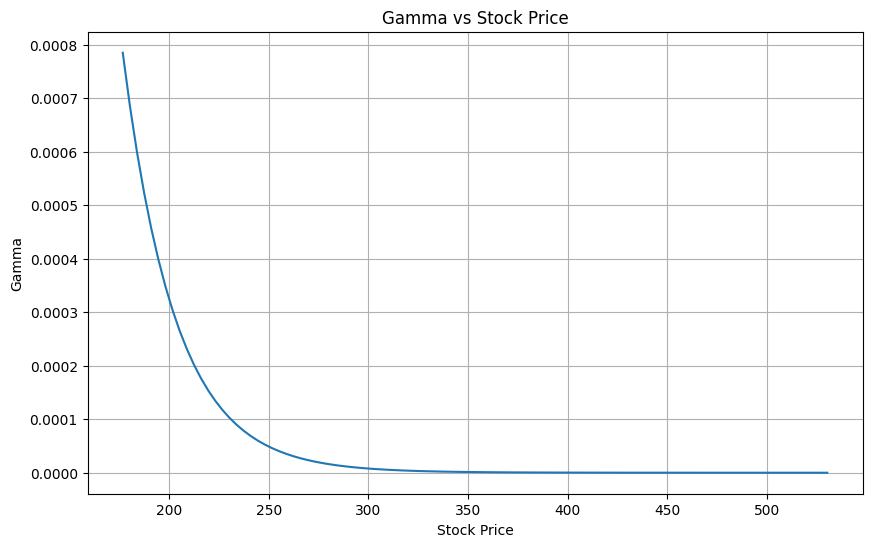

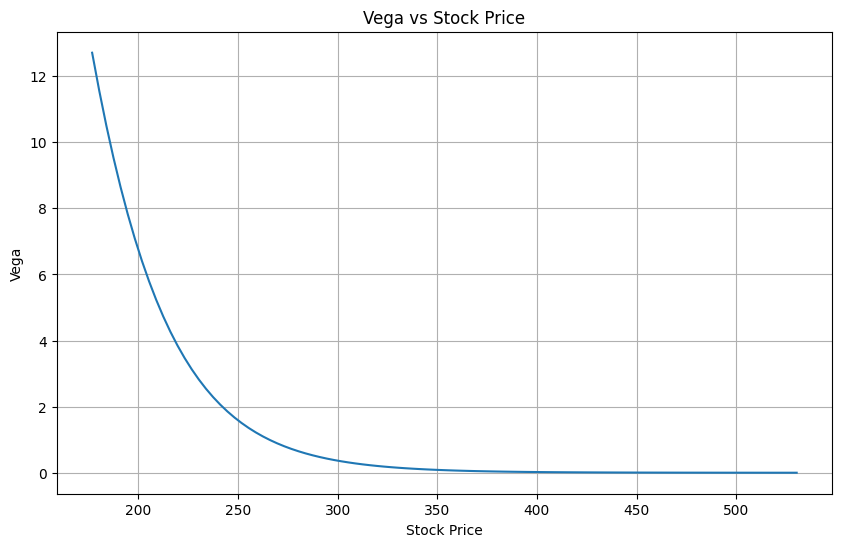

In [ ]:

# YAHOO FINANCE + BLACK-SCHOLES OPTION PRICING MODEL


# 1. IMPORT LIBRARIES

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from datetime import datetime

# 2. USER INPUTS
while True:
    ticker = input("Enter stock ticker (Example: AAPL): ").strip().upper()

    if ticker.isalpha():
        break

    print("Invalid input. Please enter a stock ticker, such as AAPL.")

r = float(input("Enter risk-free rate in % (Example: 4.5): "))

r = r / 100


# 3. FETCH DATA FROM YAHOO FINANCE

stock = yf.Ticker(ticker)

try:
    history = stock.history(
        period="1y",
        interval="1d",
        auto_adjust=True
    )

    if history is None or history.empty:
        print("No stock data retrieved.")
        print("Check the ticker symbol or try again later.")
        raise SystemExit

except Exception as error:
    print("Yahoo Finance data retrieval failed:", error)
    raise SystemExit

S = float(history["Close"].dropna().iloc[-1])

print("\nCurrent available stock price:", round(S, 2))

# Latest available stock price

S = float(history["Close"].dropna().iloc[-1])

print("\nCurrent available stock price:", round(S, 2))


# 4. CALCULATE HISTORICAL VOLATILITY

# Calculate daily percentage returns

daily_returns = np.log(
    history["Close"] / history["Close"].shift(1)
).dropna()

# Calculate standard deviation of daily returns

daily_volatility = daily_returns.std()

# Annualise volatility using 252 trading days

sigma = daily_volatility * np.sqrt(252)

print("Annualised volatility:", round(sigma * 100, 2), "%")


# 5. GET OPTION EXPIRY DATES

expiries = stock.options

if len(expiries) == 0:
  raise ValueError("No option expiry dates available for this ticker.")

print("\nAvailable expiry dates:")

for i, date in enumerate(expiries):
  print(i, ":", date)

expiry_number = int(input("\nSelect expiry number: "))

expiry = expiries[expiry_number]


# 6. GET OPTION CHAIN

option_chain = stock.option_chain(expiry)

calls = option_chain.calls
puts = option_chain.puts

print("\nAvailable strike prices:")

print(calls["strike"].to_list())

E = float(input("\nEnter strike price: "))
if E <= 0:
    raise ValueError("Strike price must be positive.")

call_row = calls[calls["strike"] == E]
put_row = puts[puts["strike"] == E]

if call_row.empty or put_row.empty:
    raise ValueError("Selected strike is not available for both calls and puts.")


# Find the selected strike in Yahoo's option chain

call_row = calls[calls["strike"] == E]

put_row = puts[puts["strike"] == E]

if call_row.empty or put_row.empty:
  raise ValueError("Selected strike is not available for both calls and puts.")


# Market option prices (midpoint of bid and ask)

call_bid = float(call_row["bid"].iloc[0])
call_ask = float(call_row["ask"].iloc[0])

put_bid = float(put_row["bid"].iloc[0])
put_ask = float(put_row["ask"].iloc[0])

call_market = np.nan
put_market = np.nan

if call_bid > 0 and call_ask >= call_bid:
    call_market = (call_bid + call_ask) / 2

if put_bid > 0 and put_ask >= put_bid:
    put_market = (put_bid + put_ask) / 2

# 7. CALCULATE TIME TO EXPIRY
from datetime import datetime, time

expiry_date = datetime.strptime(expiry, "%Y-%m-%d")

today = datetime.now()

expiry_datetime = datetime.combine(
    expiry_date.date(),
    time(21, 0)
)

days_remaining = (expiry_datetime - today).total_seconds() / 86400

T = days_remaining / 365

# 8. DIVIDEND YIELD

try:
    dividends = stock.dividends

    if not dividends.empty:

        today = pd.Timestamp.now(tz=dividends.index.tz)

        one_year_ago = today - pd.Timedelta(days=365)

        annual_dividends = dividends[
            dividends.index >= one_year_ago
        ].sum()

        q = annual_dividends / S

    else:
        q = 0

except Exception as error:
    print("Could not retrieve dividend data:", error)
    q = 0

print("Dividend yield:", round(q * 100, 4), "%")

# 9. CALCULATE d1 AND d2
d1 = (np.log(S / E) +(r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)


# 10. NORMAL DISTRIBUTION VALUES

N_d1 = norm.cdf(d1)

N_d2 = norm.cdf(d2)

N_minus_d1 = norm.cdf(-d1)

N_minus_d2 = norm.cdf(-d2)

phi_d1 = norm.pdf(d1)


# 11. BLACK-SCHOLES CALL AND PUT PRICES

call_price = (S * np.exp(-q * T) * N_d1- E * np.exp(-r * T) * N_d2)


put_price = (E * np.exp(-r * T) * N_minus_d2- S * np.exp(-q * T) * N_minus_d1)


# 12. GREEKS

# DELTA

call_delta = np.exp(-q * T) * N_d1

put_delta = np.exp(-q * T) * (N_d1 - 1)


# GAMMA

gamma = (np.exp(-q * T) * phi_d1/ (S * sigma * np.sqrt(T)))


# THETA
call_theta= (-S*np.exp(-q*T)*phi_d1*sigma/ (2*np.sqrt(T))-r*E*np.exp(-r*T)*N_d2+q*S*np.exp(-q*T)*N_d1)


put_theta = (-S*np.exp(-q*T)*phi_d1*sigma/(2*np.sqrt(T))+r*E*np.exp(-r*T)*N_minus_d2-q*S*np.exp(-q*T)*N_minus_d1)


# VEGA

vega = S * np.exp(-q * T) * phi_d1 * np.sqrt(T)


# RHO

call_rho = E * T * np.exp(-r * T) * N_d2

put_rho = -E * T * np.exp(-r * T) * N_minus_d2

# 13. DISPLAY RESULTS

print(" BLACK-SCHOLES RESULTS")

print("Stock:", ticker)

print("Stock price:", round(S, 4))

print("Strike price:", E)

print("Expiry:", expiry)

print("Days remaining:", days_remaining)

print("Risk-free rate:", round(r * 100, 2), "%")

print("Dividend yield:", round(q * 100, 2), "%")

print("Volatility:", round(sigma * 100, 2), "%")


print("d1:", round(d1, 6))

print("d2:", round(d2, 6))


print("THEORETICAL CALL PRICE:", round(call_price, 4))

print("THEORETICAL PUT PRICE:", round(put_price, 4))


print("MARKET CALL MID PRICE:", round(call_market, 4))

print("MARKET PUT MID PRICE:", round(put_market, 4))


print("CALL DELTA:", round(call_delta, 6))

print("PUT DELTA:", round(put_delta, 6))

print("GAMMA:", round(gamma, 6))

print("CALL THETA per day:", round(call_theta / 365, 6))

print("PUT THETA per day:", round(put_theta / 365, 6))

print("VEGA per 1% volatility:", round(vega / 100, 6))

print("CALL RHO per 1% rate:", round(call_rho / 100, 6))

print("PUT RHO per 1% rate:", round(put_rho / 100, 6))





# 14. GRAPH 1: CALL AND PUT PRICE VS STOCK PRICE


stock_prices = np.linspace(S * 0.5, S * 1.5, 100)

d1_graph=(np.log(stock_prices/E)+(r-q+0.5*sigma**2)*T)/(sigma * np.sqrt(T))

d2_graph =d1_graph-sigma*np.sqrt(T)


call_graph = (
    stock_prices * np.exp(-q*T) * norm.cdf(d1_graph)
    - E * np.exp(-r*T) * norm.cdf(d2_graph)
)
put_graph = (E*np.exp(-r*T)*norm.cdf(-d2_graph)-stock_prices*np.exp(-q*T)*norm.cdf(-d1_graph))


plt.figure(figsize=(10, 6))

plt.plot(stock_prices, call_graph, label="Call Price")

plt.plot(stock_prices, put_graph, label="Put Price")

plt.axvline(E, linestyle="--", label="Strike Price")

plt.axvline(S, linestyle=":", label="Current Stock Price")

plt.xlabel("Stock Price")

plt.ylabel("Option Price")

plt.title("Black-Scholes: Option Price vs Stock Price")

plt.legend()

plt.grid()

plt.show()


# 15. GRAPH 2: DELTA VS STOCK PRICE

delta_graph = np.exp(-q * T) * norm.cdf(d1_graph)

plt.figure(figsize=(10, 6))

plt.plot(stock_prices, delta_graph, label="Call Delta")

plt.xlabel("Stock Price")

plt.ylabel("Delta")

plt.title("Call Delta vs Stock Price")

plt.legend()

plt.grid()

plt.show()



# 16. GRAPH 3: GAMMA VS STOCK PRICE

gamma_graph = (np.exp(-q*T) *norm.pdf(d1_graph)/(stock_prices * sigma * np.sqrt(T)))

plt.figure(figsize=(10, 6))

plt.plot(stock_prices, gamma_graph)

plt.xlabel("Stock Price")

plt.ylabel("Gamma")

plt.title("Gamma vs Stock Price")

plt.grid()

plt.show()


# 17. GRAPH 4: VEGA VS STOCK PRICE

vega_graph = (stock_prices*np.exp(-q*T)*norm.pdf(d1_graph) * np.sqrt(T))

plt.figure(figsize=(10, 6))

plt.plot(stock_prices, vega_graph)

plt.xlabel("Stock Price")

plt.ylabel("Vega")

plt.title("Vega vs Stock Price")

plt.grid()

plt.show()